# Lecture 23 notebook: who else trades

This notebook replays Lecture 23. Every figure and number of the lecture comes from a script in `scripts/`, next to this notebook; each runs in a fresh process, so that memory is freed after every step. The scripts reuse Lecture 22's order tables and footprint measures (`l22_styles.py`), unchanged.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings | |
| 1 | What we see, and who did it: the key chart | §1 |
| 2 | Four footprints, with the answer known | §2 |
| 3 | What is at work on Bybit: H10, H11, H12 | §3 |
| 4 | When, and in what conditions: H13, H14 | §4 |
| 5 | What our quotes meet: H21, H22, and all twelve tests corrected | §5 |
| 6 | A test of your own: a quoter that never meets the sniper | §6 |

**Two switches, both off by default.**

* **Off (default): the figures and tables only.** All figures are redrawn from the small results shipped in `results/` (one file per day for §3 to §5) and match the lecture's. No market data is needed; it takes about a minute.
* **`RUN_CHECK = True`: one day of data.** §3, §4 and §5 are recomputed for `CHECK_DAY` and compared with the shipped day. It needs Lecture 22's order table for that day (`L22_OUT`, default `BYBIT_ROOT/interim/l22`), Lecture 19's book state (`L19_OUT`) and the Binance aggTrades of Lecture 20 (`BINANCE_ROOT`). About two minutes.
* **`RUN_ALL = True`: everything.** Every day in Lecture 22's order folder (about a minute a day), the laboratory part of the key chart, the tests and the charts. About an hour.

With a switch on, results go to `L22_OUT/l23_results`, starting from a copy of the shipped ones (without the day files, for `RUN_ALL`), so the lecture's own results are never overwritten; figures are saved in `figures/` as `nb_*`.

## 0. Settings

In [1]:
import json, os, shutil, subprocess, sys, time
from pathlib import Path
import numpy as np, polars as pl, psutil
from IPython.display import Image, display

HERE = Path.cwd(); SCRIPTS, FIG = HERE / "scripts", HERE / "figures"; FIG22 = HERE.parent / "22-a-market-that-reacts" / "figures"
sys.path[:0] = [str(SCRIPTS)]
import l23 as L
CHECK_DAY = "2025-10-15"                                                   # the day recomputed by RUN_CHECK (out of sample)
RUN_CHECK = False                                                          # True: recompute CHECK_DAY (about two minutes)
RUN_ALL = False                                                            # True: recompute everything (about an hour)

SHIPPED = HERE / "results"; WORK = L.L22.OUT / "l23_results"; DIRS = ("s3_days", "s4_hours", "s5_days")
if RUN_CHECK or RUN_ALL:                                                  # recomputed results never overwrite the shipped ones
    WORK.mkdir(parents=True, exist_ok=True)
    for f in SHIPPED.glob("*.json"):
        if not (WORK / f.name).exists(): shutil.copy(f, WORK / f.name)
    for d in DIRS:
        if not RUN_ALL and not (WORK / d).exists(): shutil.copytree(SHIPPED / d, WORK / d)
RES = WORK if (RUN_CHECK or RUN_ALL) else SHIPPED
pl.Config.set_tbl_rows(50); pl.Config.set_fmt_str_lengths(90); pl.Config.set_tbl_width_chars(220); pl.Config.set_tbl_cols(20)
print("order tables:", L.L22.OUT / "orders", "| results read from:", RES)
print(f"free memory: {psutil.virtual_memory().available / 1e9:.1f} GB of {psutil.virtual_memory().total / 1e9:.1f} GB")


def run(script, *args, show=False):
    "Run a script of this lecture in a fresh process; figures as nb_*, results to RES."
    t0 = time.time()
    env = {**os.environ, "BYBIT_ROOT": str(L.L22.ROOT), "L19_OUT": str(L.L22.STATE.parent if L.L22.STATE.name == "state" else L.L22.STATE), "L22_OUT": str(L.L22.OUT),
           "BINANCE_ROOT": str(L.L22.BN_RAW.parents[2]), "L23_RESULTS": str(RES), "L23_PREFIX": "nb_", "PYTHONIOENCODING": "utf-8"}
    p = subprocess.run([sys.executable, "-I", str(SCRIPTS / script), *args], capture_output=True, text=True, encoding="utf-8", env=env)
    if p.returncode:
        print(p.stdout[-2000:], p.stderr[-4000:]); raise RuntimeError(f"{script} failed")
    print(f"{script} {' '.join(args)}: {time.time() - t0:.0f} s")
    if show: print(p.stdout)


def pictures(*names, folder=None):
    for nm in names:
        f = (folder or FIG) / (f"{nm}.png" if folder else f"nb_{nm}.png")
        display(Image(filename=str(f))) if f.exists() else print("not drawn yet:", f.name)


def result(name):
    return json.loads((RES / name).read_text(encoding="utf-8"))

order tables: D:\trading-data\bybit\interim\l22\orders | results read from: C:\Users\maxgn\AppData\Local\Temp\claude\c--Users-maxgn-New-Trading-Models\55dd06ff-9b76-4978-a2f2-2a54d515eb84\scratchpad\systematic-trading-notes\lectures\23-trading-styles\results
free memory: 0.9 GB of 16.9 GB


## 1. What we see, and who did it

`l23_key.py` draws the key chart: four minutes of Lecture 22's laboratory market, once with each order's owner and once as the public feed shows them, with the footprint measures; then four real minutes of Bybit on 1 October 2025 with the same measures. With `RUN_ALL` the laboratory is simulated again and the Bybit window searched again. The last line scores the measures against the laboratory's truth.

l23_key.py : 5 s
lab 1729 orders | in runs 8 | runs 1 | sniper-like 9 | in clock seconds 76
bybit 345 orders | in runs 53 | runs 4 | sniper-like 18 | in clock seconds 20
lab truth: orders in runs that are TWAP 1.0 | sniper-like that are sniper 0.33 | TWAP orders found in runs 0.15



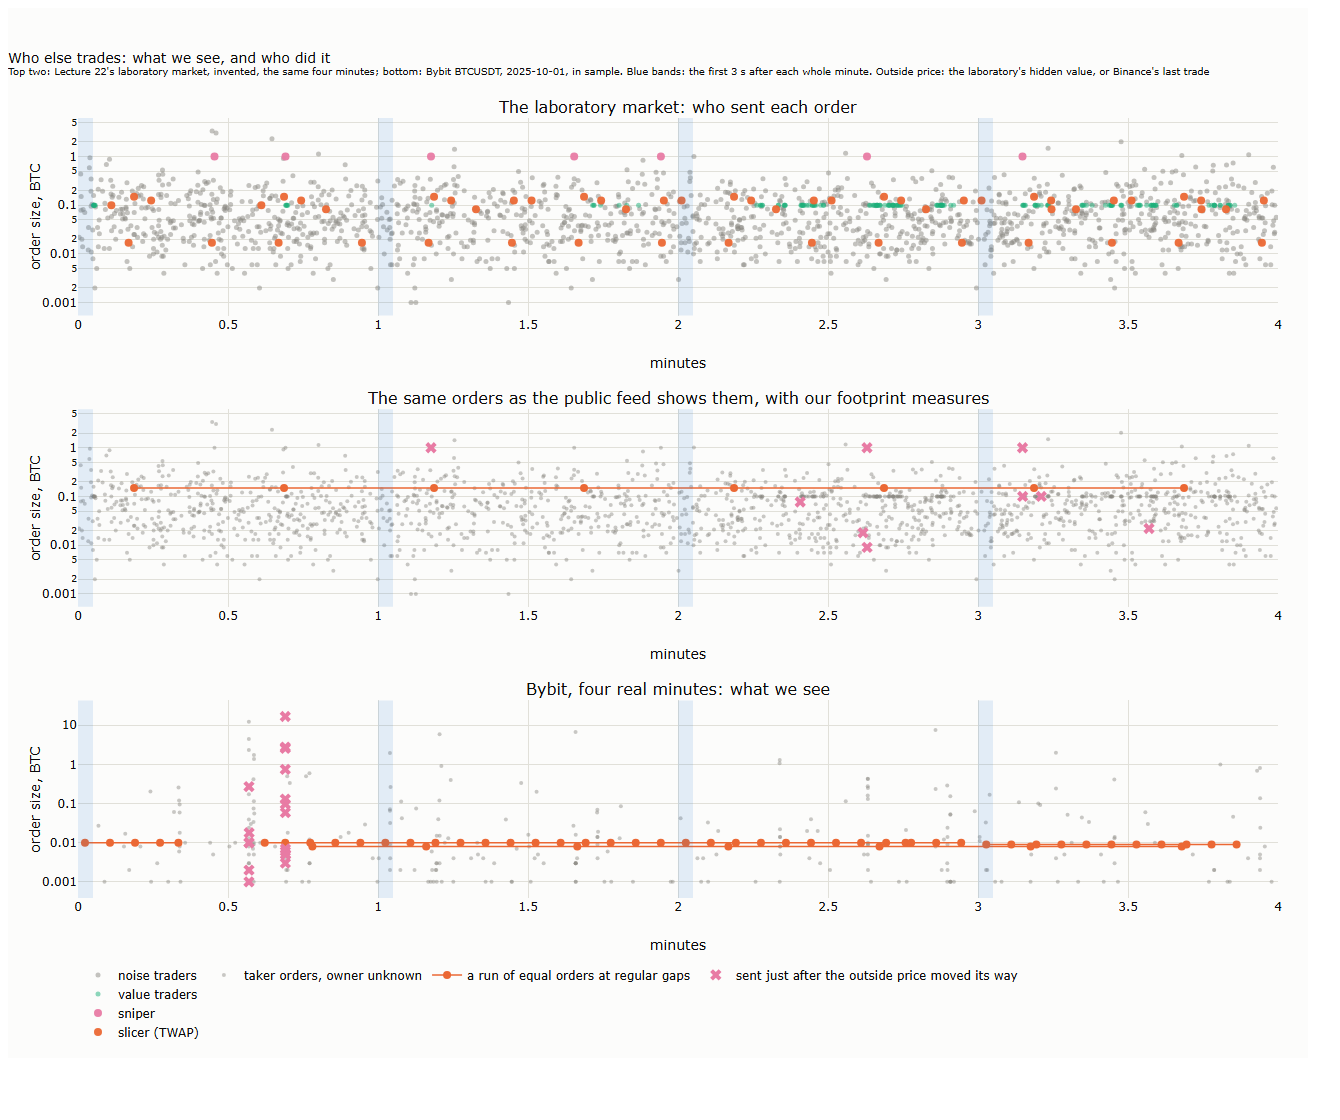

In [2]:
run("l23_key.py", *(["--run"] if RUN_ALL else []), show=True)
pictures("23_key")

## 2. Four footprints, with the answer known

The cards of §2 rest on Lecture 22's laboratory: step 3 (the sniper), step 4 (the slicer and the run rule) and step 5 (the clock). Their figures are shown here as Lecture 22 drew them; Lecture 22's notebook simulates them again. The run rule itself is short enough to read in full.

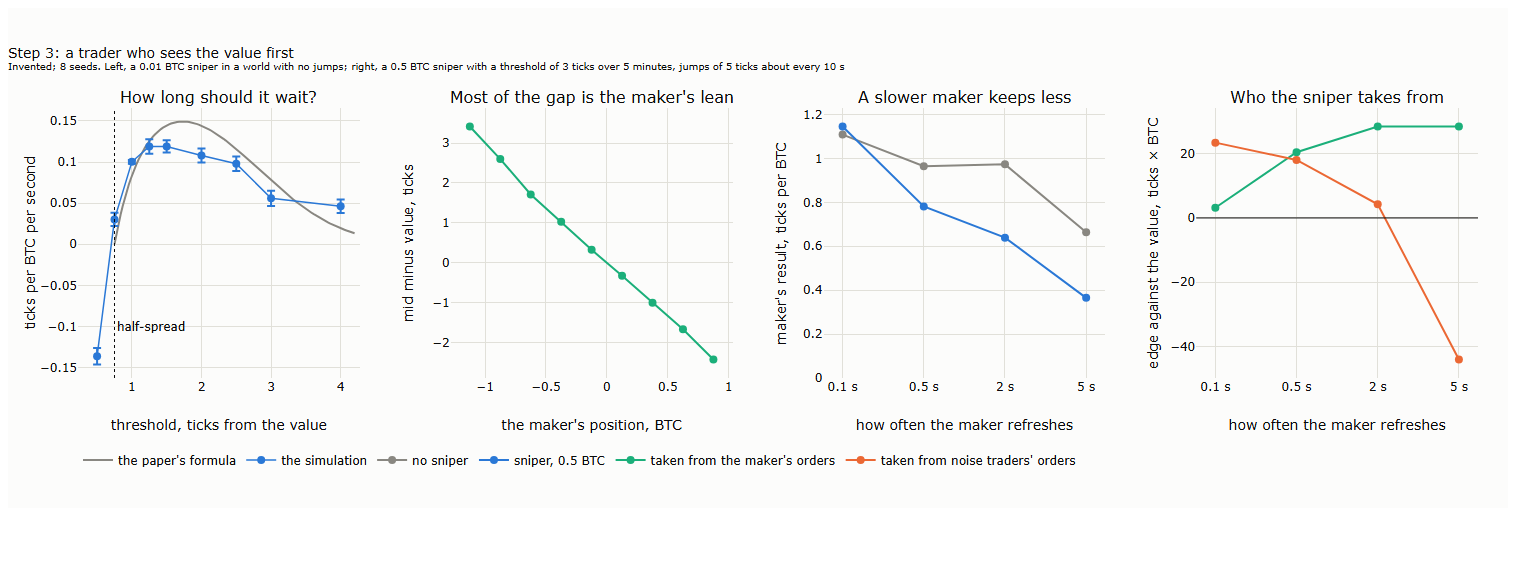

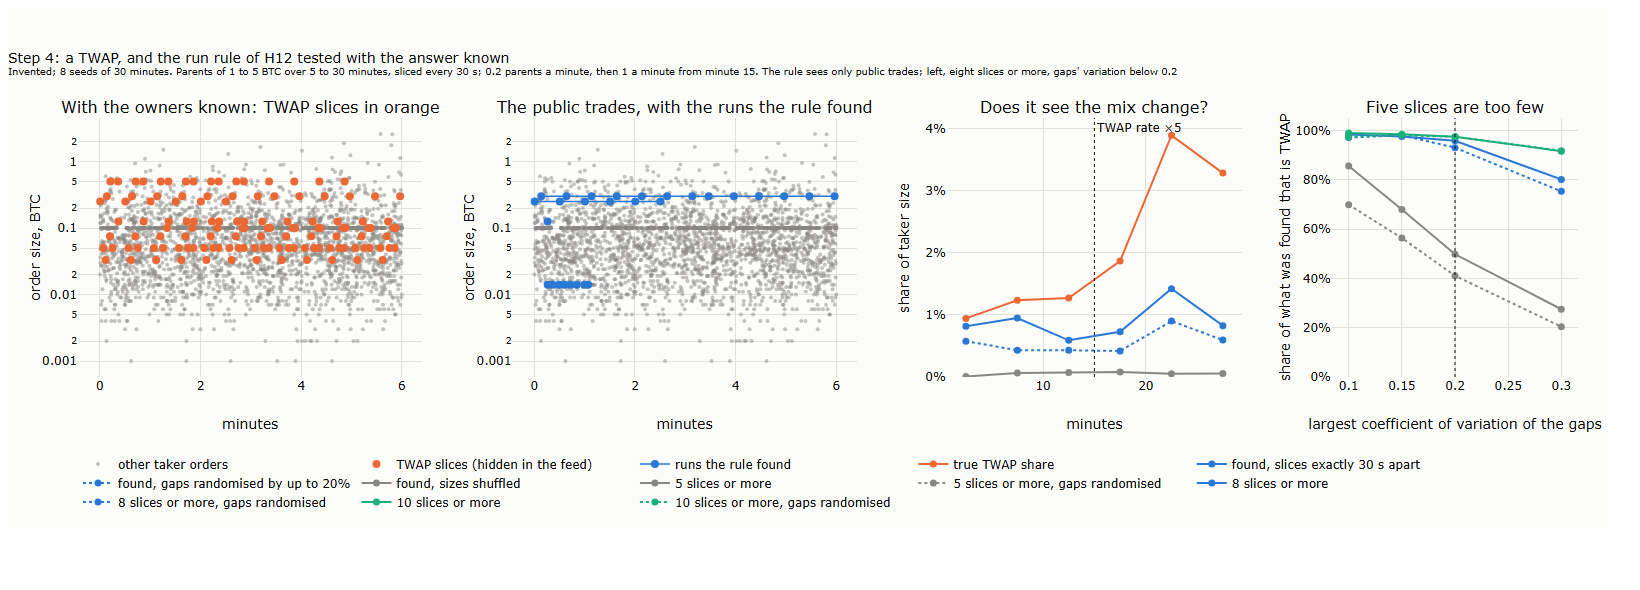

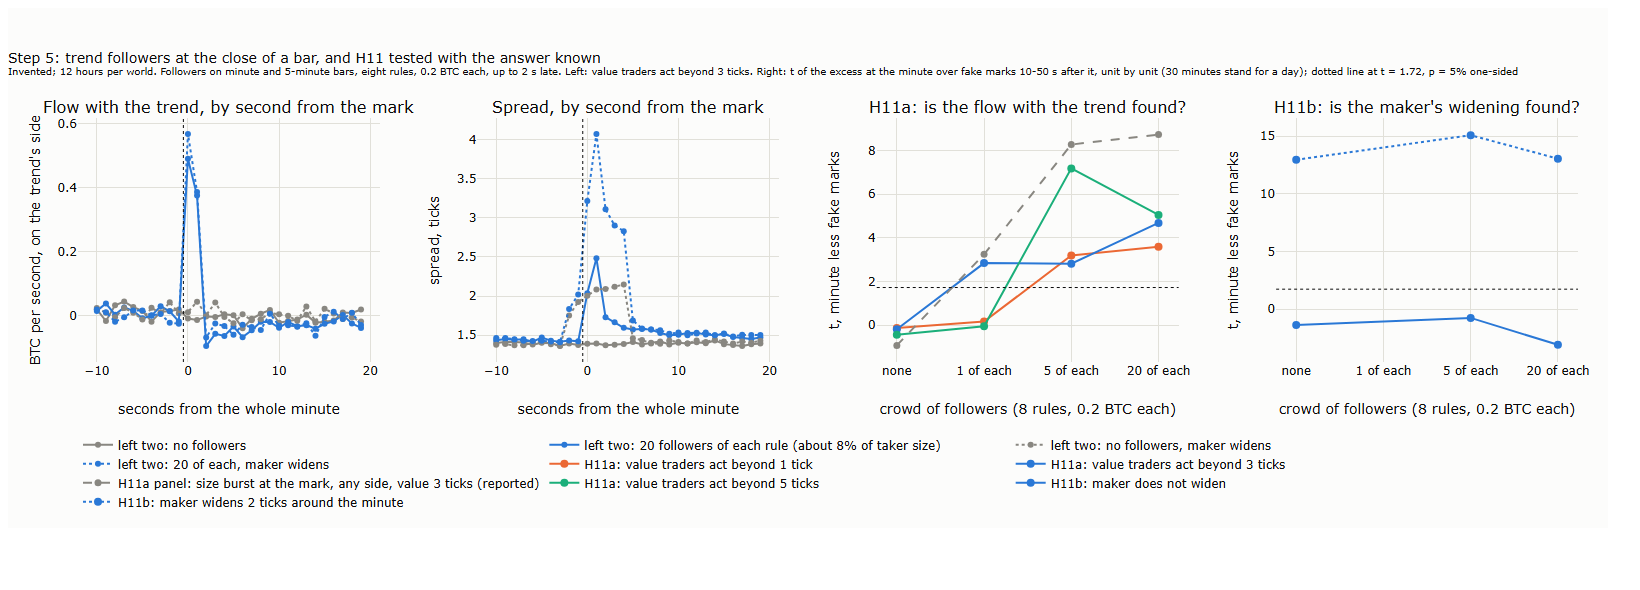

def runs(O, cv=0.2, min_n=8, min_gap=1000):
    """H12's runs in a table of taker orders O (t in ms, side, q in BTC, sorted by t): min_n or more consecutive orders of one exact size on one side whose gaps have a coefficient of variation
    below cv and a mean of at least min_gap ms. Greedy: from each order, extend while the gaps stay below cv; a run found, start after it. Returns one row per run, and for each order of O the run it belongs to (-1 if none)."""
    tt, sd, qq = O["t"].to_numpy(), O["side"].to_numpy(), O["q"].to_numpy(); lab = np.full(len(tt), -1); out = []
    o = np.lexsort((tt, qq, sd)); cut = np.nonzero((np.diff(sd[o]) != 0) | (np.diff(qq[o]) != 0))[0] + 1
    for g in np.split(o, cut):
        if len(g) < min_n: continue
        d = np.diff(tt[g]).astype(float); i = 0
        while i <= len(g) - min_n:
            k = i + 1
            while k < len(d) and d[i:k + 1].std() < cv * d[i:k + 1].mean(): k += 1
            if k - i + 1 >= min_n and d[i:k].mean() >= min_gap

In [3]:
pictures("22_sim_step3", "22_sim_step4", "22_sim_step5", folder=FIG22)
import inspect, l22_styles as St
print(inspect.getsource(St.runs))

## 3. What is at work on Bybit

`l23_s3.py` computes, day by day, H10 (the move after sniper-like orders, net of Lecture 22's matched controls), H11 (whole minutes against fake marks) and H12 (runs against shuffled sizes); `--tests` turns the days into the tests; `l23_s3_charts.py` draws the figure. With `RUN_CHECK` the check day is recomputed and compared with the shipped one.

l23_s3_charts.py : 4 s
H10 other [0.4  0.66 0.94 1.15 1.78] sniper-like [2.98 3.26 4.   5.31 6.51]



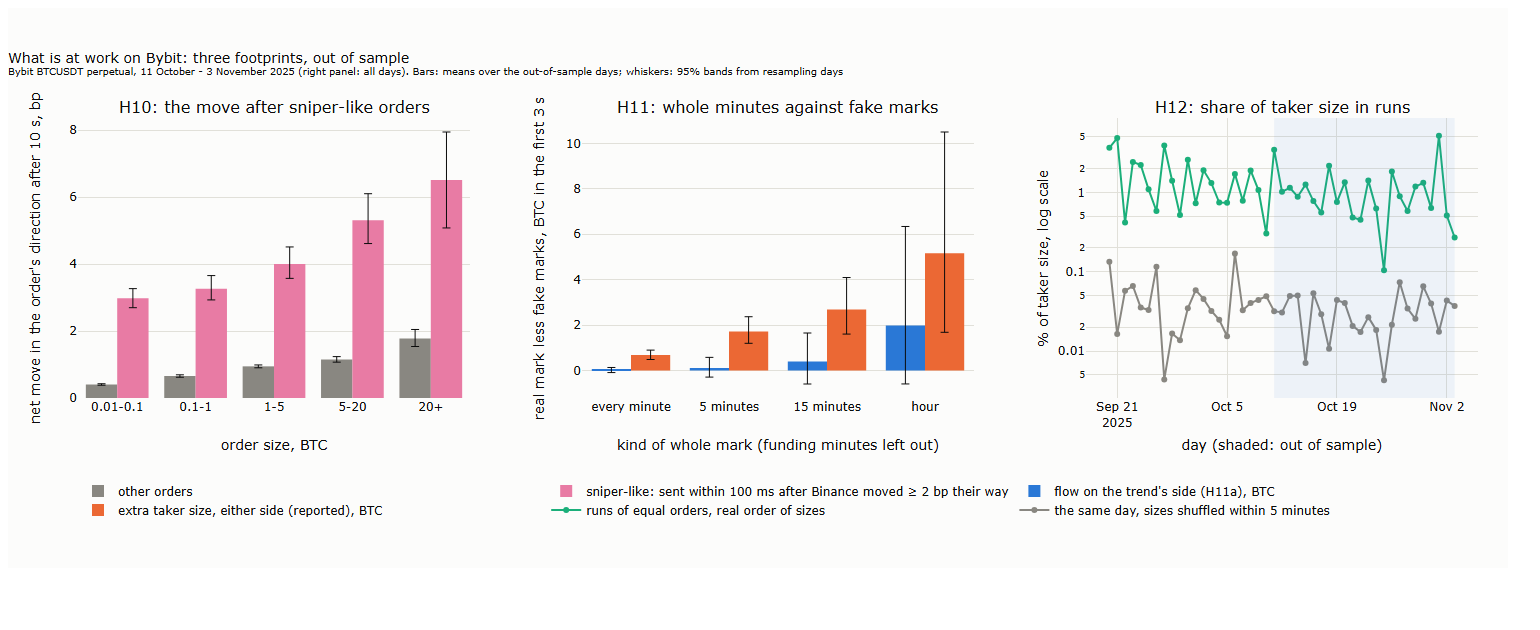

test,measure,out of sample,p
str,str,f64,f64
"""H10""","""net R(10 s), sniper-like less other, bp""",2.7012,0.0
"""H11a""","""flow with the trend, real less fake marks, BTC""",0.0251,0.3375
"""H11b""","""share of wide quotes before the mark, real less fake""",-0.0004,1.0
"""H12""","""share in runs, real less shuffled""",0.0117,0.0
"""reported""","""size burst in the first 3 s, BTC""",0.6825,0.0
"""reported""","""spread after the mark, real less fake""",0.0146,0.0001


sniper-like: share of orders 0.034 | of size 0.09 | by size class {'0.01-0.1': 2.57, '0.1-1': 2.6, '1-5': 3.06, '20+': 4.73, '5-20': 4.16}
runs out of sample: 3215 | gaps within 1 s of 30.22 s: 0.34 of runs, 0.61 of their size


In [4]:
if RUN_CHECK:
    for d in DIRS: (RES / d / f"{CHECK_DAY}.json").unlink(missing_ok=True); (RES / d / f"{CHECK_DAY}.parquet").unlink(missing_ok=True)
    run("l23_s3.py", CHECK_DAY); run("l23_s4.py", CHECK_DAY); run("l23_s5.py", CHECK_DAY)
    a, b = json.loads((SHIPPED / "s3_days" / f"{CHECK_DAY}.json").read_text()), result(f"s3_days/{CHECK_DAY}.json")
    a5, b5 = json.loads((SHIPPED / "s5_days" / f"{CHECK_DAY}.json").read_text()), result(f"s5_days/{CHECK_DAY}.json")
    rows = [("runs share", a["h12"]["share"], b["h12"]["share"]), ("H11a, real mark", a["h11"]["real"]["a"], b["h11"]["real"]["a"]), ("size burst, real mark", a["h11"]["real"]["g"], b["h11"]["real"]["g"]),
            ("sniper-like adverse move, BTC·bp", a5["h21"]["sniper"]["m10000"], b5["h21"]["sniper"]["m10000"]), ("Binance moves, 2 bp", a5["h22"]["2"]["n"], b5["h22"]["2"]["n"])]
    display(pl.DataFrame([(k, round(float(x), 4), round(float(y), 4)) for k, x, y in rows], schema=["measure", "lecture", "this run"], orient="row"))
if RUN_ALL: run("l23_s3.py"); run("l23_s4.py"); run("l23_s5.py")
if RUN_CHECK or RUN_ALL: run("l23_s3.py", "--tests"); run("l23_s4.py", "--tests"); run("l23_s5.py", "--tests")
run("l23_s3_charts.py", show=True)
pictures("23_s3_styles")
T3 = result("s3_tests.json")["out"]; h = T3["H11"]
display(pl.DataFrame([("H10", "net R(10 s), sniper-like less other, bp", T3["H10"]["stat"], T3["H10"]["p"]), ("H11a", "flow with the trend, real less fake marks, BTC", h["a"]["diff"], h["a"]["p"]),
                      ("H11b", "share of wide quotes before the mark, real less fake", h["x"]["diff"], h["x"]["p"]), ("H12", "share in runs, real less shuffled", T3["H12"]["stat"], T3["H12"]["p"]),
                      ("reported", "size burst in the first 3 s, BTC", h["g"]["diff"], h["g"]["p"]), ("reported", "spread after the mark, real less fake", h["s"]["diff"], h["s"]["p"])],
                     schema=["test", "measure", "out of sample", "p"], orient="row").with_columns(pl.col("out of sample").round(4), pl.col("p").round(4)))
print("sniper-like: share of orders", round(T3["H10"]["share_orders"], 3), "| of size", round(T3["H10"]["share_size"], 3), "| by size class", {k: round(v, 2) for k, v in T3["H10"]["by_class"].items()})
print("runs out of sample:", T3["H12"]["n_runs"], "| gaps within 1 s of 30.22 s:", round(T3["H12"]["near30"], 2), "of runs,", round(T3["H12"]["size_near30"], 2), "of their size")

## 4. When, and in what conditions

`l23_s4.py` gives each taker order one footprint (sliced, else sniper-like, else large, else other), adds the clock-like excess after whole minutes, and sums them by hour with the hour's volatility; `--tests` runs H13 and H14; `l23_s4_charts.py` draws the figure.

l23_s4_charts.py : 3 s


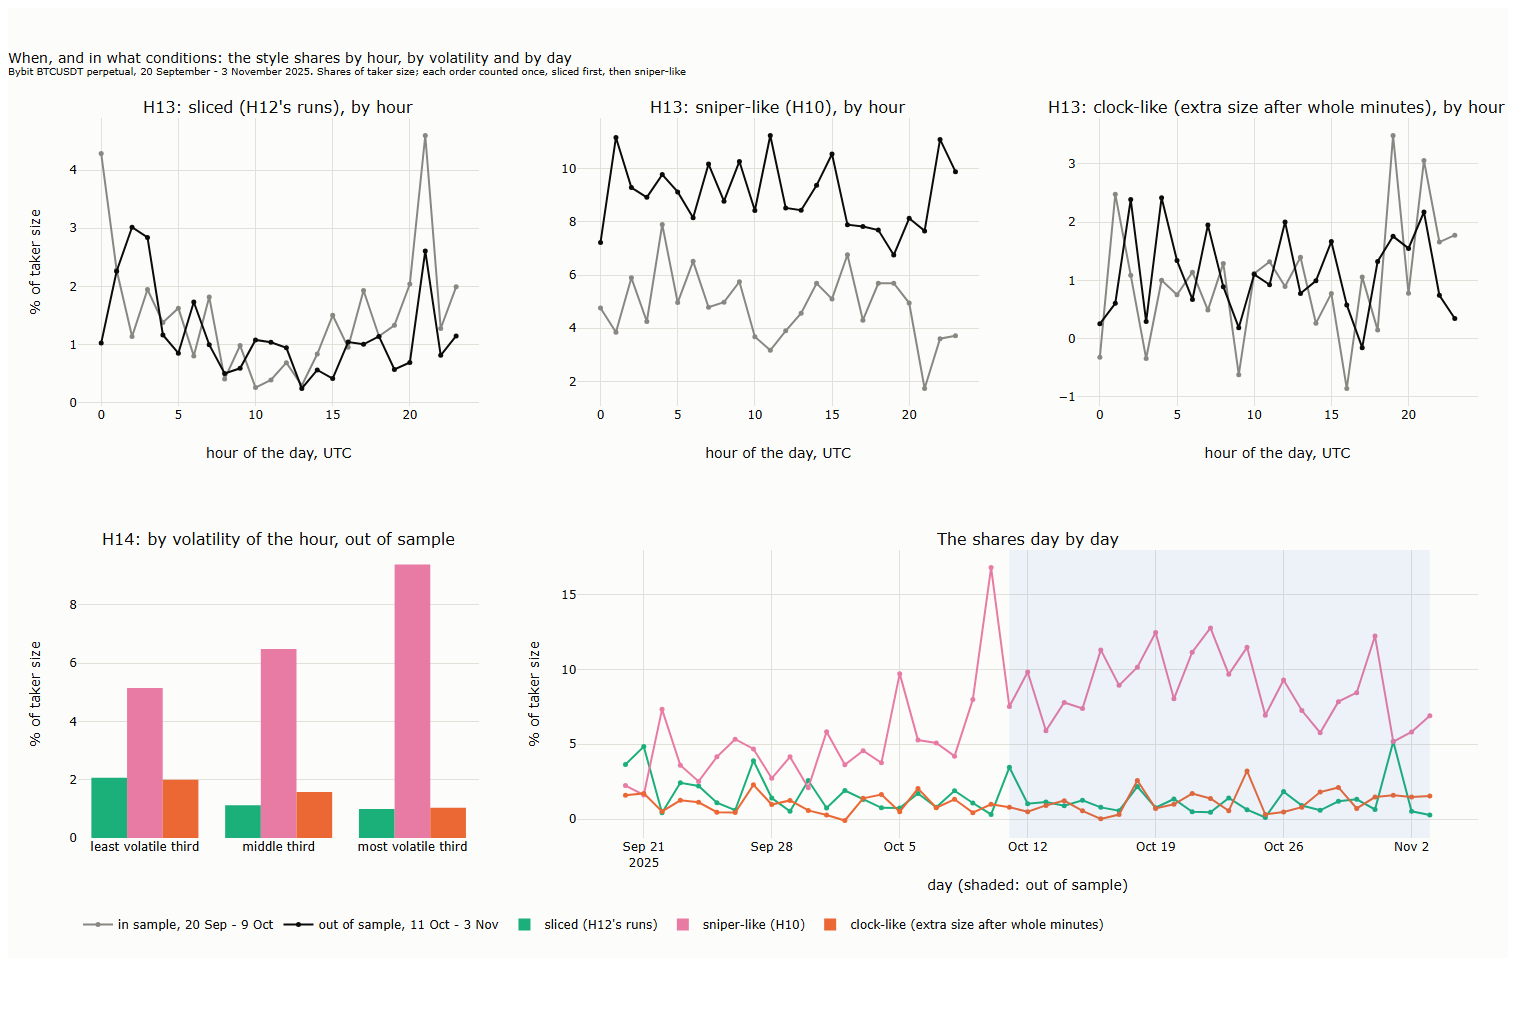

test,footprint,statistic,p
str,str,f64,f64
"""H13""","""sliced""",0.3113,0.095
"""H13""","""sniper""",-0.1652,0.699
"""H13""","""clock""",0.1939,0.0875
"""H14""","""sliced""",-0.007,0.1865
"""H14""","""sniper""",0.0463,0.0
"""H14""","""clock""",-0.0142,1.0


footprint,calm %,middle %,volatile %
str,f64,f64,f64
"""sliced""",2.07,1.12,0.99
"""sniper""",5.15,6.49,9.39
"""clock""",2.0,1.58,1.04


shares in / out of sample: {'in': {'sliced': 1.37, 'sniper': 5.07, 'clock': 0.85, 'large': 63.42}, 'out': {'sliced': 1.04, 'sniper': 9.01, 'clock': 1.12, 'large': 56.93}}


In [5]:
run("l23_s4_charts.py")
pictures("23_s4_when")
T4 = result("s4_tests.json")
display(pl.DataFrame([("H13", s, T4["H13"][s]["rho"], T4["H13"][s]["p"]) for s in ("sliced", "sniper", "clock")] + [("H14", s, T4["H14"][s]["diff"], T4["H14"][s]["p"]) for s in ("sliced", "sniper", "clock")],
                     schema=["test", "footprint", "statistic", "p"], orient="row").with_columns(pl.col("statistic").round(4), pl.col("p").round(4)))
display(pl.DataFrame([(s, *[round(100 * x, 2) for x in T4["H14"][s]["by_third"]]) for s in ("sliced", "sniper", "clock")], schema=["footprint", "calm %", "middle %", "volatile %"], orient="row"))
print("shares in / out of sample:", {k: {s: round(100 * v, 2) for s, v in d.items()} for k, d in T4["shares"].items()})

## 5. What our quotes meet

`l23_s5.py` computes the makers' adverse move by footprint (H21) and the delay from a Binance move to the first Bybit taker order in its direction, against random moments (H22); `l23_s5_charts.py` draws the figure. The last table is §5.1: all twelve p-values of the lecture, corrected together.

l23_s5_charts.py : 4 s
median delay ms, 2 bp: 30 | 5 bp: 30



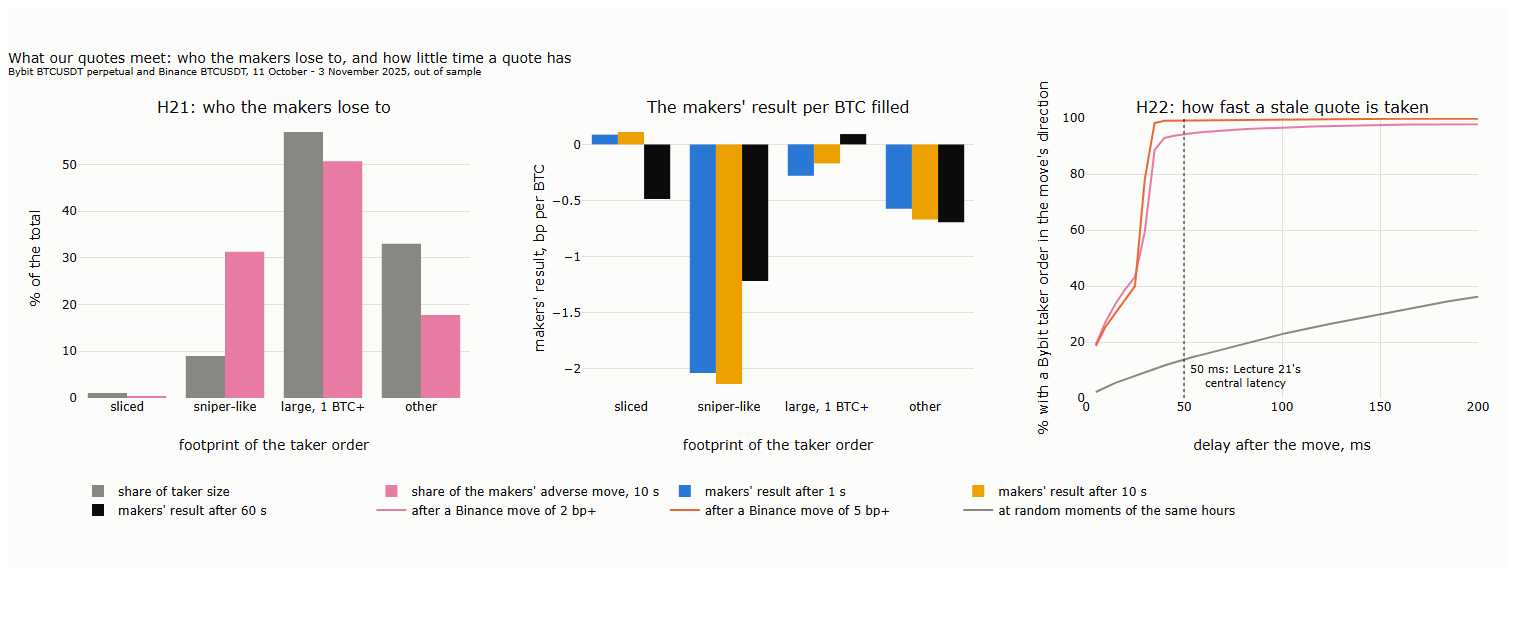

footprint,% of size,% of adverse move,"makers 1 s, bp/BTC",10 s,60 s
str,f64,f64,f64,f64,f64
"""sliced""",1.0,0.3,0.09,0.11,-0.49
"""sniper""",9.0,31.3,-2.04,-2.14,-1.22
"""large""",56.9,50.7,-0.28,-0.17,0.09
"""other""",33.0,17.8,-0.57,-0.67,-0.69


Binance move,moves,% within 10 ms,50 ms,100 ms,"random, 50 ms"
str,i64,f64,f64,f64,f64
"""2 bp""",22305,28.6,94.3,96.6,14.0
"""5 bp""",2901,26.5,99.2,99.6,14.2


test,p,q,verdict
str,f64,f64,str
"""H10""",0.0005,0.0012,"""holds"""
"""H12""",0.0005,0.0012,"""holds"""
"""H14 sniper""",0.0005,0.0012,"""holds"""
"""H21""",0.0005,0.0012,"""holds"""
"""H22""",0.0005,0.0012,"""holds"""
"""H13 clock""",0.0875,0.1629,"""fails"""
"""H13 sliced""",0.095,0.1629,"""fails"""
"""H14 sliced""",0.1865,0.2798,"""fails"""
"""H11a""",0.3375,0.45,"""fails"""


In [6]:
run("l23_s5_charts.py", show=True)
pictures("23_s5_quotes")
T5 = result("s5_tests.json")["out"]; A = T5["H21"]
display(pl.DataFrame([(f, round(100 * A["size_share"][f], 1), round(100 * A["adverse_share"][f], 1), *[round(A["maker"][f][k], 2) for k in ("m1000", "m10000", "m60000")]) for f in ("sliced", "sniper", "large", "other")],
                     schema=["footprint", "% of size", "% of adverse move", "makers 1 s, bp/BTC", "10 s", "60 s"], orient="row"))
display(pl.DataFrame([(j + " bp", v["n"], *[round(100 * v["real"][str(l)] if str(l) in v["real"] else 100 * v["real"][l], 1) for l in (10, 50, 100)], round(100 * v["rand"]["50"], 1)) for j, v in T5["H22"].items()],
                     schema=["Binance move", "moves", "% within 10 ms", "50 ms", "100 ms", "random, 50 ms"], orient="row"))
fam = {"H10": T3["H10"]["p"], "H11a": T3["H11"]["a"]["p"], "H11b": T3["H11"]["x"]["p"], "H12": T3["H12"]["p"], **{f"H13 {s}": T4["H13"][s]["p"] for s in ("sliced", "sniper", "clock")},
       **{f"H14 {s}": T4["H14"][s]["p"] for s in ("sliced", "sniper", "clock")}, "H21": A["p"], "H22": T5["H22"]["2"]["p"]}
p = np.array([max(v, 1 / 2000) for v in fam.values()]); o = np.argsort(p); m = len(p); q = np.empty(m); q[o] = np.minimum(1, np.minimum.accumulate((p[o] * m / np.arange(1, m + 1))[::-1])[::-1])
display(pl.DataFrame({"test": list(fam), "p": p.round(4), "q": q.round(4), "verdict": ["holds" if x < 0.05 else "fails" for x in q]}).sort("p"))

## 6. A test of your own: a quoter that never meets the sniper

What would the makers have earned if no sniper-like order had reached them? The cell takes the shipped totals of §5 and leaves the sniper-like footprint out. It is an upper bound: a real quoter cannot know in advance which order is coming, and the snipers would turn to other quotes. Exercise: repeat it in sample, and with the large orders left out as well.

In [7]:
D = [json.loads(f.read_text(encoding="utf-8")) for f in sorted((RES / "s5_days").glob("*.json")) if L.L22.OUT_SAMPLE[0] <= f.stem <= L.L22.OUT_SAMPLE[1]]
tot = {f: np.sum([[d["h21"].get(f, {}).get(k, 0.0) for k in ("size", "cost", "m10000")] for d in D], 0) for f in ("sliced", "sniper", "large", "other")}
res = lambda fs: (sum(tot[f][1] - tot[f][2] for f in fs) / sum(tot[f][0] for f in fs))
print(f"makers' result after 10 s, bp per BTC: all fills {res(tot):.2f} | without sniper-like fills {res([f for f in tot if f != 'sniper']):.2f}")

makers' result after 10 s, bp per BTC: all fills -0.51 | without sniper-like fills -0.35
